# 04 · Results (test split, computed once)
All tables are read from `results/tables/` written by `scripts/05_evaluate.py`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
P = ROOT / 'data' / 'processed'; TAB = ROOT / 'results' / 'tables'; FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)


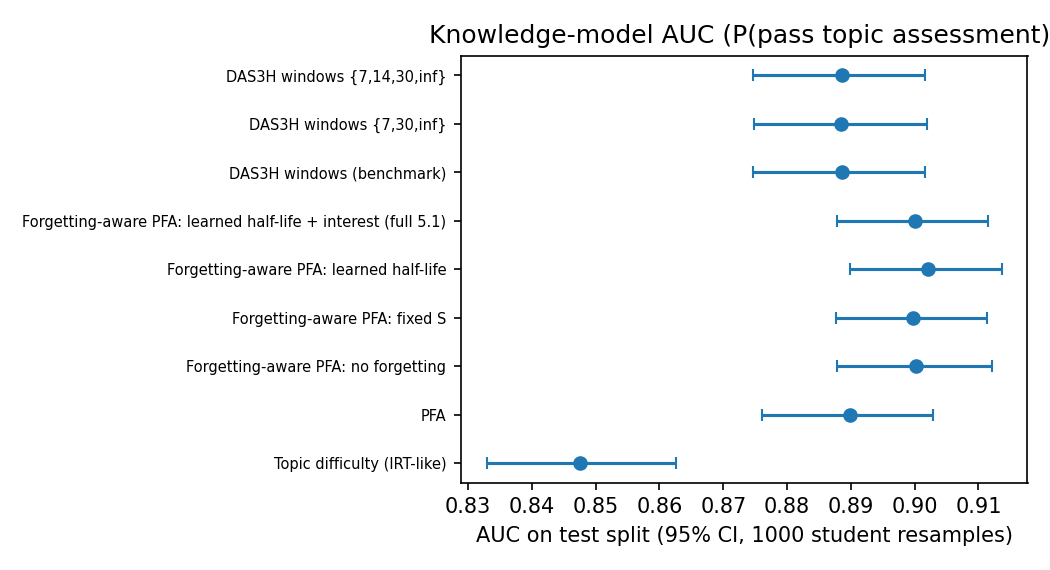

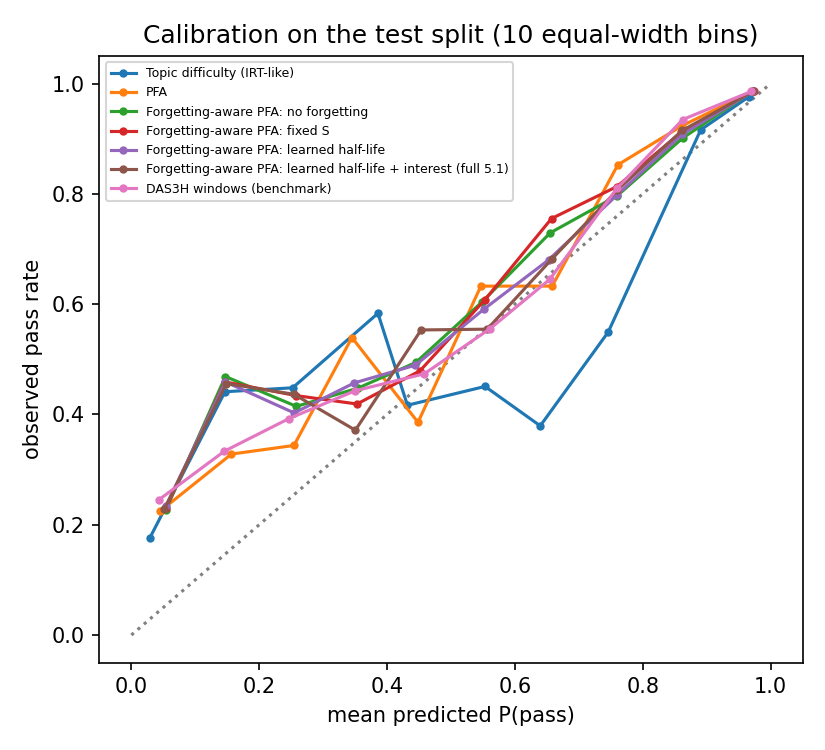

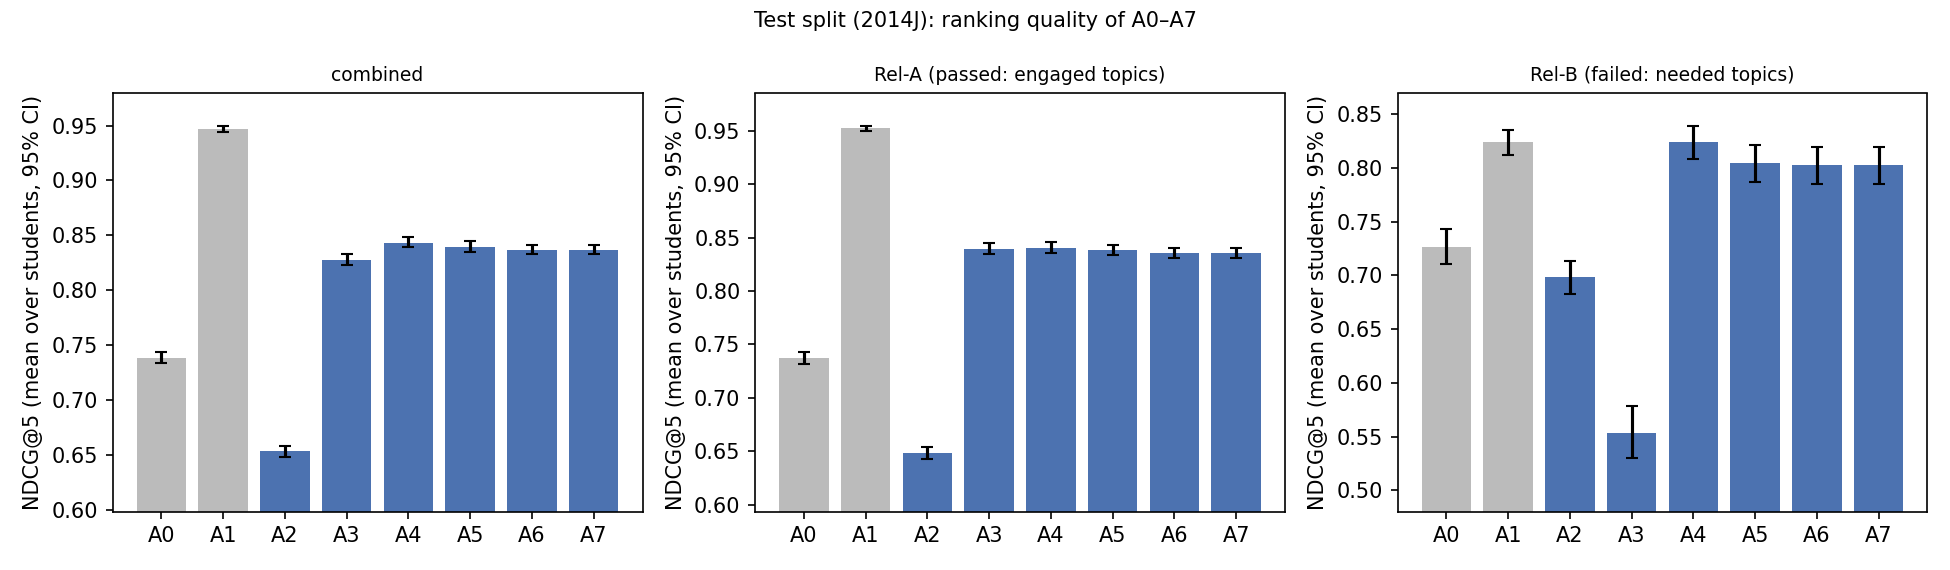

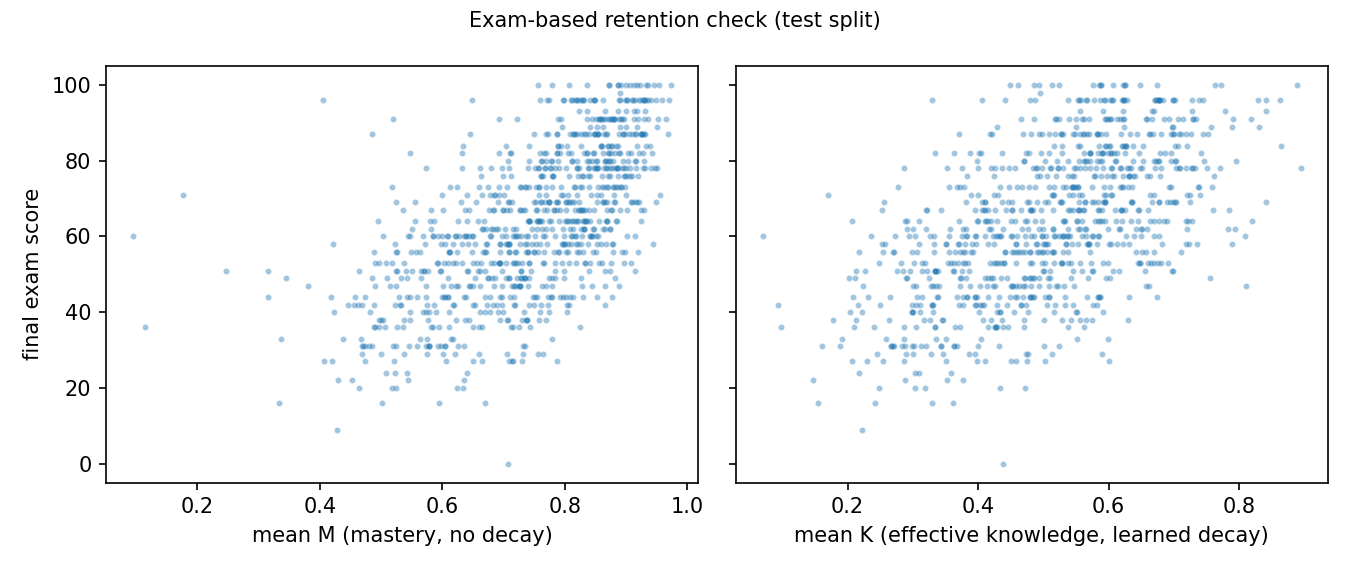

In [2]:
from IPython.display import Image, display
for f in ['model_auc_test.png', 'calibration_test.png', 'ranking_ndcg5_test.png', 'exam_check_scatter.png']:
    display(Image(str(FIG / f)))

In [3]:
for f in ['model_metrics_test.csv','coefficients.csv','ranking_metrics_test.csv','simulated_gain_test.csv','exam_retention_check.csv','wilcoxon_holm.csv','sensitivity.csv','fairness_gaps.csv','dkt_comparison.csv']:
    p = TAB/f
    print('='*20, f); display(pd.read_csv(p)) if p.exists() else print('missing')

==================== model_metrics_test.csv


,model,label,n_rows,n_students,AUC,logloss,logloss_lo,logloss_hi,Brier,Brier_lo,Brier_hi,RMSE,RMSE_lo,RMSE_hi,MAE,RMSE_score,MAE_score,ECE,AUC_lo,AUC_hi
0,majority,Majority,14976,3064,0.500000,0.186389,0.174738,0.197399,0.043246,0.039473,0.046810,0.207956,0.198679,0.216357,0.102286,0.252351,0.190409,0.018072,NaN,NaN
1,topic_difficulty,Topic difficulty (IRT-like),14976,3064,0.847596,0.137506,0.128247,0.146727,0.034221,0.031265,0.037157,0.184989,0.176819,0.192761,0.075895,0.251601,0.201721,0.016109,0.832926,0.862562
2,pfa,PFA,14976,3064,0.889833,0.131252,0.122468,0.140336,0.033304,0.030534,0.035949,0.182493,0.174740,0.189603,0.081513,0.239395,0.193731,0.024921,0.876134,0.902822
3,none,Forgetting-aware PFA: no forgetting,14976,3064,0.900246,0.128718,0.120319,0.137171,0.033440,0.030681,0.036232,0.182867,0.175160,0.190346,0.078978,0.239238,0.194501,0.021258,0.887831,0.912063
4,fixed,Forgetting-aware PFA: fixed S,14976,3064,0.899765,0.129061,0.120786,0.137600,0.033594,0.030879,0.036355,0.183288,0.175723,0.190670,0.079612,0.239033,0.194448,0.021930,0.887641,0.911346
5,learned,Forgetting-aware PFA: learned half-life,14976,3064,0.902091,0.127621,0.119325,0.136115,0.033258,0.030533,0.035948,0.182367,0.174736,0.189601,0.078242,0.239745,0.195146,0.020290,0.889800,0.913655
6,learnedI,Forgetting-aware PFA: learned half-life + inte...,14976,3064,0.900116,0.128459,0.120111,0.137138,0.033366,0.030673,0.036094,0.182662,0.175136,0.189984,0.078994,0.239284,0.194543,0.021062,0.887887,0.911555
7,das3h,DAS3H windows (benchmark),14976,3064,0.888547,0.132664,0.124160,0.141782,0.033321,0.030486,0.036003,0.182541,0.174602,0.189746,0.083497,0.237794,0.191872,0.025661,0.874657,0.901625
8,das3h_7_30_inf,"DAS3H windows {7,30,inf}",14976,3064,0.888464,0.132796,0.124260,0.141885,0.033357,0.030580,0.036025,0.182640,0.174873,0.189803,0.083618,0.237670,0.191787,0.025754,0.874851,0.901973
9,das3h_7_14_30_inf,"DAS3H windows {7,14,30,inf}",14976,3064,0.888547,0.132664,0.124160,0.141782,0.033321,0.030486,0.036003,0.182541,0.174602,0.189746,0.083497,0.237794,0.191872,0.025661,0.874657,0.901625


==================== coefficients.csv


,param,estimate,ci_lo,ci_hi,boot_sd,excludes_0,model,n_boot,S
0,beta[DDD-1],3.470719,3.279095,3.702962,0.102991,True,none,200,NaN
1,beta[DDD-2],3.167219,2.849803,3.580079,0.186157,True,none,200,NaN
2,beta[DDD-3],3.150244,2.829986,3.464523,0.170912,True,none,200,NaN
3,beta[DDD-4],1.462696,1.146999,1.675147,0.138301,True,none,200,NaN
4,beta[DDD-5],1.403911,1.161840,1.642201,0.124679,True,none,200,NaN
...,...,...,...,...,...,...,...,...,...
64,theta_K,2.081702,1.781970,2.416631,0.151482,True,learnedI,200,NaN
65,phi_0,6.363457,5.550699,7.322788,0.462548,True,learnedI,200,NaN
66,phi_c,-0.872464,-1.350682,-0.438658,0.237570,True,learnedI,200,NaN
67,phi_d,0.537353,0.055801,0.949977,0.239102,True,learnedI,200,NaN


==================== ranking_metrics_test.csv


,config,label,relevance,metric,value,ci_lo,ci_hi,n_students
0,A0,Random,A,P@3,0.518551,0.510890,0.526477,2704
1,A0,Random,A,R@3,0.583609,0.577006,0.590557,2704
2,A0,Random,A,NDCG@3,0.607514,0.599629,0.615166,2704
3,A0,Random,A,P@5,0.488757,0.482103,0.495755,2704
4,A0,Random,A,R@5,0.906442,0.902956,0.910155,2704
...,...,...,...,...,...,...,...,...
139,A7,A6 + data-derived prerequisites,AB,R@3,0.797976,0.792188,0.804165,2754
140,A7,A6 + data-derived prerequisites,AB,NDCG@3,0.811666,0.806229,0.817567,2754
141,A7,A6 + data-derived prerequisites,AB,P@5,0.499356,0.492809,0.505355,2754
142,A7,A6 + data-derived prerequisites,AB,R@5,0.925042,0.921378,0.928683,2754


... (8 outputs left out)

==================== fairness_gaps.csv


,attribute,what,largest_gap
0,disability,AUC learnedI,0.016611
1,disability,AUC none,0.013504
2,disability,NDCG@5 A3,0.010783
3,disability,NDCG@5 A6,0.007509
4,gender,AUC learnedI,0.003593
5,gender,AUC none,0.004867
6,gender,NDCG@5 A3,0.015085
7,gender,NDCG@5 A6,0.028717
8,imd_band,AUC learnedI,0.070234
9,imd_band,AUC none,0.062186


==================== dkt_comparison.csv


,split,model,rows,n_rows,AUC,logloss,Brier,RMSE,MAE,AUC_lo,AUC_hi
0,val,dkt,steps with >= 1 earlier response,7177,0.789350,0.212765,0.057150,0.239061,0.107609,0.766966,0.808865
1,val,pfa,steps with >= 1 earlier response,7177,0.889695,0.182633,0.050461,0.224635,0.101536,0.874941,0.903050
2,val,das3h,steps with >= 1 earlier response,7177,0.891752,0.182577,0.050201,0.224057,0.103346,0.876610,0.904942
3,val,none,steps with >= 1 earlier response,7177,0.904429,0.178727,0.051207,0.226290,0.100549,0.891449,0.917444
4,val,learned,steps with >= 1 earlier response,7177,0.905055,0.177807,0.051013,0.225860,0.099908,0.892128,0.917552
5,val,learnedI,steps with >= 1 earlier response,7177,0.904508,0.177914,0.050942,0.225703,0.100151,0.891464,0.917306
6,test,dkt,steps with >= 1 earlier response,11912,0.782540,0.170871,0.043547,0.208678,0.092210,0.764002,0.801374
7,test,pfa,steps with >= 1 earlier response,11912,0.882064,0.148222,0.038181,0.195400,0.092215,0.867687,0.895186
8,test,das3h,steps with >= 1 earlier response,11912,0.880598,0.150000,0.038287,0.195670,0.094531,0.864821,0.894584
9,test,none,steps with >= 1 earlier response,11912,0.895997,0.143490,0.038007,0.194954,0.087622,0.884038,0.907727
